# SINet — Camouflaged Object Detection in Images & Video
### Complete project code, explained step by step
**EE5340 Video Analytics · IIT Guwahati · Prof. Prithwijit Guha**
Akash Shukla (264152017) · Abdul Quadir (264152001) · Sanjeev Singh (264152013)

This notebook holds **all the code of our project in one place**, in the order the data flows:

| Part | What it contains | Source |
|---|---|---|
| 1 | Setup & imports | — |
| 2 | ResNet-50 two-branch backbone | SINet repo (`Src/backbone/ResNet.py`) |
| 3 | `BasicConv2d` + Receptive Field (RF) module | SINet repo (`Src/SINet.py`) |
| 4 | Partial Decoder Components (PDC-SM, PDC-IM) | SINet repo (`Src/SINet.py`) |
| 5 | Search Attention (SA) | SINet repo (`Src/SearchAttention.py`) |
| 6 | Full SINet model + **shape walkthrough demo** | SINet repo (`Src/SINet.py`) |
| 7 | Dataset & DataLoader | SINet repo (`Src/utils/Dataloader.py`) |
| 8 | Loss + training loop + **one-step training demo** | SINet repo (`MyTrain.py`, `trainer.py`), modernised by us |
| 9 | Inference + metrics (MAE, IoU, F-β) | **Ours** (`test_images.py`) |
| 10 | Video extension: EMA smoothing + tracking + **demo** | **Ours** (`video_inference.py`) |

**Runs on a normal laptop CPU.** Every demo cell works without a GPU, dataset or pretrained weights. If `SINet_40.pth` is present, Part 9/10 also run real inference.

**To run in VS Code:** install the *Python* and *Jupyter* extensions, open this file, click **Select Kernel → Python**, then run cells one by one (Shift+Enter).

---
## Part 1 — Setup & imports
Run the first cell once if the packages are missing.

In [1]:
# Run once if needed (remove the # to execute)
# %pip install torch torchvision opencv-python numpy scipy matplotlib pillow

In [2]:
import os, math, time, csv
import numpy as np
import cv2
import scipy.stats as st
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.parameter import Parameter
import torch.utils.data as data
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

torch.manual_seed(0); np.random.seed(0)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', DEVICE)

# ---- paths (change if your files are elsewhere) ----
MODEL_PATH = './code/SINet_40.pth'          # pretrained SINet weights (optional)
TEST_IMAGE_DIR = './code/Dataset/TestDataset/COD10K/Image'   # optional
TEST_GT_DIR    = './code/Dataset/TestDataset/COD10K/GT'      # optional
INPUT_VIDEO = './code/input.mp4'                             # optional

PyTorch 2.15.0+cu132 | device: cpu


---
## Part 2 — Backbone: ResNet-50 with two branches
**Why:** we need features at several scales: fine texture (edges, colour) and deep semantics (object shape).

**Key idea of SINet:** layers 1–2 are **shared**, but layers 3–4 exist **twice**:
- `layer3_1`, `layer4_1` → used by the **Search Module** (find roughly *where*)
- `layer3_2`, `layer4_2` → used by the **Identification Module** (segment *exactly what*), after attention

| Feature | Layer | Shape for 352×352 input |
|---|---|---|
| X0 | conv1 + maxpool | 64 × 88 × 88 |
| X1 | layer1 | 256 × 88 × 88 |
| X2 | layer2 | 512 × 44 × 44 |
| X3 | layer3 | 1024 × 22 × 22 |
| X4 | layer4 | 2048 × 11 × 11 |

`Bottleneck` is the standard ResNet block: 1×1 → 3×3 → 1×1 convolutions plus a skip connection.

In [3]:
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, planes * 4, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * 4)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))      # 1x1: reduce channels
        out = self.relu(self.bn2(self.conv2(out)))    # 3x3: spatial features (stride here downsamples)
        out = self.bn3(self.conv3(out))               # 1x1: expand channels x4
        if self.downsample is not None:               # match shape for the skip connection
            residual = self.downsample(x)
        return self.relu(out + residual)              # residual connection


class ResNet_2Branch(nn.Module):
    # ResNet-50 with two copies of layer3/layer4 (modified from torchvision ResNet)
    def __init__(self):
        super().__init__()
        self.inplanes = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(Bottleneck, 64, 3)               # shared
        self.layer2 = self._make_layer(Bottleneck, 128, 4, stride=2)    # shared
        self.layer3_1 = self._make_layer(Bottleneck, 256, 6, stride=2)  # search branch
        self.layer4_1 = self._make_layer(Bottleneck, 512, 3, stride=2)  # search branch

        self.inplanes = 512                                             # restart from layer2 output
        self.layer3_2 = self._make_layer(Bottleneck, 256, 6, stride=2)  # identification branch
        self.layer4_2 = self._make_layer(Bottleneck, 512, 3, stride=2)  # identification branch

        for m in self.modules():                                        # He initialisation
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1); m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion))
        layers = [block(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * block.expansion
        layers += [block(self.inplanes, planes) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

---
## Part 3 — `BasicConv2d` and the Receptive Field (RF) module
**Problem:** camouflaged objects can be tiny (a pipefish) or large (a leopard). One kernel size can't see both.

**RF module** = 4 parallel branches with growing receptive fields:

| Branch | Convs | Dilation | Effective view |
|---|---|---|---|
| b0 | 1×1 | – | 1×1 |
| b1 | 1×1 → 1×3 → 3×1 → 3×3 | 3 | 7×7 |
| b2 | 1×1 → 1×5 → 5×1 → 3×3 | 5 | 11×11 |
| b3 | 1×1 → 1×7 → 7×1 → 3×3 | 7 | 15×15 |

$$\mathrm{RF}(x)=\mathrm{ReLU}\Big(\mathrm{Bconv}_{3\times3}([b_0;b_1;b_2;b_3]) + \mathrm{Bconv}_{1\times1}(x)\Big)$$

- **Dilation:** a 3×3 kernel with dilation *d* covers a (2d+1)×(2d+1) area using only 9 weights.
- **1×k then k×1:** cheaper than one k×k kernel.
- Every RF block outputs **32 channels**, so all scales can be fused later.

**Our observation:** `BasicConv2d` creates `self.relu`, but `forward` **never uses it**. So it is really Conv + BN only, even though the paper says Conv + BN + ReLU.

In [4]:
class BasicConv2d(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride=1, padding=0, dilation=1):
        super().__init__()
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride,
                              padding=padding, dilation=dilation, bias=False)
        self.bn = nn.BatchNorm2d(out_planes)
        self.relu = nn.ReLU(inplace=True)   # defined ...

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        return x                            # ... but never applied (Conv + BN only)


class RF(nn.Module):
    # Revised from RFBNet (ECCV 2018)
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.relu = nn.ReLU(True)
        self.branch0 = nn.Sequential(BasicConv2d(in_channel, out_channel, 1))
        self.branch1 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 3), padding=(0, 1)),
            BasicConv2d(out_channel, out_channel, kernel_size=(3, 1), padding=(1, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=3, dilation=3))
        self.branch2 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 5), padding=(0, 2)),
            BasicConv2d(out_channel, out_channel, kernel_size=(5, 1), padding=(2, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=5, dilation=5))
        self.branch3 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 7), padding=(0, 3)),
            BasicConv2d(out_channel, out_channel, kernel_size=(7, 1), padding=(3, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=7, dilation=7))
        self.conv_cat = BasicConv2d(4 * out_channel, out_channel, 3, padding=1)   # fuse 4 branches
        self.conv_res = BasicConv2d(in_channel, out_channel, 1)                   # shortcut

    def forward(self, x):
        x_cat = self.conv_cat(torch.cat((self.branch0(x), self.branch1(x),
                                         self.branch2(x), self.branch3(x)), dim=1))
        return self.relu(x_cat + self.conv_res(x))

In [5]:
# DEMO: RF keeps the spatial size and maps any channel count to 32
rf_demo = RF(512, 32).eval()
x = torch.randn(1, 512, 44, 44)
with torch.no_grad():
    y = rf_demo(x)
print('RF input :', tuple(x.shape))
print('RF output:', tuple(y.shape), '-> same 44x44 size, channels reduced to 32')

RF input : (1, 512, 44, 44)
RF output: (1, 32, 44, 44) -> same 44x44 size, channels reduced to 32


---
## Part 4 — Partial Decoder Component (PDC)
**Job:** fuse the multi-scale RF features into one camouflage map (44×44×1).

Inputs, from **deepest to shallowest**: `x1` (11×11), `x2` (22×22), `x3` (44×44), and in the search module also `x4` (44×44, low-level).

**Key trick: multiplication as a gate.**
$$x_2' = B(\mathrm{UP}\,x_1)\otimes x_2,\qquad x_3' = B(\mathrm{UP}^2 x_1)\otimes B(\mathrm{UP}\,x_2)\otimes x_3$$
A pixel at the fine scale stays strong **only if all deeper (semantic) levels also fire there**. Deep features say *"roughly here"*; shallow features add the exact boundary.

It is **partial** because the shallowest layers (X0, X1) are not decoded fully, which saves computation.

- `PDC_SM` (search) concatenates 4 inputs → 4C channels.
- `PDC_IM` (identification) has no low-level input → 3C channels.

In [6]:
class PDC_SM(nn.Module):
    # Partial Decoder Component (Search Module)
    def __init__(self, channel):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_upsample1 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample2 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample3 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample4 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample5 = BasicConv2d(2 * channel, 2 * channel, 3, padding=1)
        self.conv_concat2 = BasicConv2d(2 * channel, 2 * channel, 3, padding=1)
        self.conv_concat3 = BasicConv2d(4 * channel, 4 * channel, 3, padding=1)
        self.conv4 = BasicConv2d(4 * channel, 4 * channel, 3, padding=1)
        self.conv5 = nn.Conv2d(4 * channel, 1, 1)                       # -> 1-channel map

    def forward(self, x1, x2, x3, x4):
        # multiplicative gating: deeper features gate shallower ones
        x2_1 = self.conv_upsample1(self.upsample(x1)) * x2
        x3_1 = self.conv_upsample2(self.upsample(self.upsample(x1))) * \
               self.conv_upsample3(self.upsample(x2)) * x3
        # progressive concatenation
        x2_2 = self.conv_concat2(torch.cat((x2_1, self.conv_upsample4(self.upsample(x1))), 1))
        x3_2 = self.conv_concat3(torch.cat((x3_1, self.conv_upsample5(self.upsample(x2_2)), x4), 1))
        return self.conv5(self.conv4(x3_2))


class PDC_IM(nn.Module):
    # Partial Decoder Component (Identification Module): same idea, without the low-level input
    def __init__(self, channel):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv_upsample1 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample2 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample3 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample4 = BasicConv2d(channel, channel, 3, padding=1)
        self.conv_upsample5 = BasicConv2d(2 * channel, 2 * channel, 3, padding=1)
        self.conv_concat2 = BasicConv2d(2 * channel, 2 * channel, 3, padding=1)
        self.conv_concat3 = BasicConv2d(3 * channel, 3 * channel, 3, padding=1)
        self.conv4 = BasicConv2d(3 * channel, 3 * channel, 3, padding=1)
        self.conv5 = nn.Conv2d(3 * channel, 1, 1)

    def forward(self, x1, x2, x3):
        x2_1 = self.conv_upsample1(self.upsample(x1)) * x2
        x3_1 = self.conv_upsample2(self.upsample(self.upsample(x1))) * \
               self.conv_upsample3(self.upsample(x2)) * x3
        x2_2 = self.conv_concat2(torch.cat((x2_1, self.conv_upsample4(self.upsample(x1))), 1))
        x3_2 = self.conv_concat3(torch.cat((x3_1, self.conv_upsample5(self.upsample(x2_2))), 1))
        return self.conv5(self.conv4(x3_2))

---
## Part 5 — Search Attention (SA): the bridge between the two stages
**Problem:** the coarse search map $C_s$ often finds only the most visible part (an owl's head, not its body).

**Solution:** blur the map with a Gaussian to *spread* attention to the neighbourhood, then use it to re-weight the features:
$$A=\sigma(C_s),\quad \tilde A=\mathcal{N}(\mathcal{G}_{31}*A),\quad C_h = X_2 \otimes \max(\tilde A, A)$$
- `_get_kernel(31, 4)` → a **31×31** Gaussian spanning ±4σ. (The paper writes σ=32, λ=4; the code's real meaning is kernel size 31 and ±4σ. This is one of our code-vs-paper findings.)
- `min_max_norm` rescales to [0, 1] after blurring.
- `max(Ã, A)` makes sure confident pixels are **never weakened**.
- Multiplying with X2 suppresses the background before identification.

In [7]:
def _get_kernel(kernlen=16, nsig=3):
    interval = (2 * nsig + 1.) / kernlen
    x = np.linspace(-nsig - interval / 2., nsig + interval / 2., kernlen + 1)
    kern1d = np.diff(st.norm.cdf(x))                  # 1D Gaussian via CDF differences
    kernel_raw = np.sqrt(np.outer(kern1d, kern1d))     # 2D kernel
    return kernel_raw / kernel_raw.sum()               # sums to 1


def min_max_norm(in_):
    max_ = in_.max(3)[0].max(2)[0].unsqueeze(2).unsqueeze(3).expand_as(in_)
    min_ = in_.min(3)[0].min(2)[0].unsqueeze(2).unsqueeze(3).expand_as(in_)
    return (in_ - min_).div(max_ - min_ + 1e-8)


class SA(nn.Module):
    # holistic / search attention
    def __init__(self):
        super().__init__()
        g = np.float32(_get_kernel(31, 4))[np.newaxis, np.newaxis, ...]   # shape (1,1,31,31)
        self.gaussian_kernel = Parameter(torch.from_numpy(g))

    def forward(self, attention, x):
        soft_attention = F.conv2d(attention, self.gaussian_kernel, padding=15)   # blur (same size)
        soft_attention = min_max_norm(soft_attention)                           # back to [0,1]
        return torch.mul(x, soft_attention.max(attention))                      # X2 * max(Ã, A)

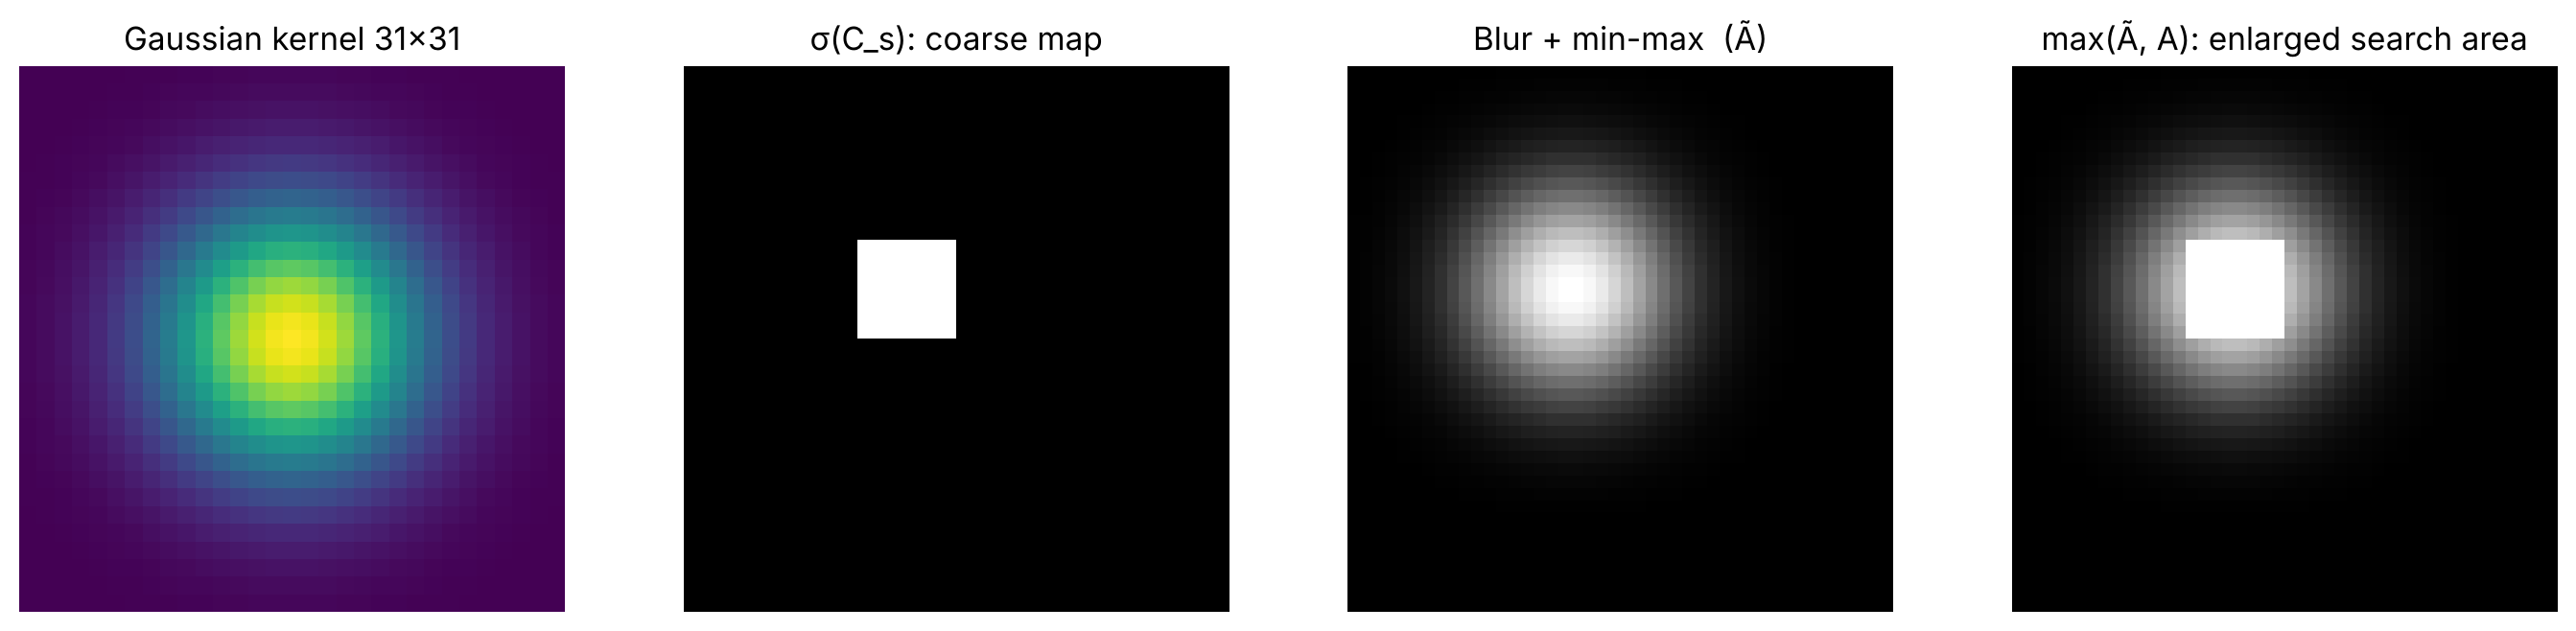

Area with attention > 0.5  before: 64 px  after: 148 px


In [8]:
# DEMO: what Search Attention does to a coarse map that found only part of the object
coarse = torch.zeros(1, 1, 44, 44)
coarse[..., 14:22, 14:22] = 1.0                       # detector found only a small patch
sa = SA()
with torch.no_grad():
    blurred = min_max_norm(F.conv2d(coarse, sa.gaussian_kernel, padding=15))
    final = blurred.max(coarse)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
ax[0].imshow(sa.gaussian_kernel[0, 0].detach(), cmap='viridis'); ax[0].set_title('Gaussian kernel 31x31')
ax[1].imshow(coarse[0, 0], cmap='gray', vmin=0, vmax=1); ax[1].set_title('σ(C_s): coarse map')
ax[2].imshow(blurred[0, 0], cmap='gray', vmin=0, vmax=1); ax[2].set_title('Blur + min-max  (Ã)')
ax[3].imshow(final[0, 0], cmap='gray', vmin=0, vmax=1); ax[3].set_title('max(Ã, A): enlarged search area')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
print('Area with attention > 0.5  before: %d px  after: %d px' % ((coarse > .5).sum(), (final > .5).sum()))

---
## Part 6 — The full SINet model
Putting it together, as in the workflow diagram on our webpage (Figure 4):

1. **Backbone (shared):** X0, X1, X2
2. **Search Module:** layer3_1/layer4_1 → X3, X4 → dense concatenation → 4 RF blocks → `PDC_SM` → coarse map $C_s$
3. **Search Attention:** $C_h = \mathrm{SA}(\sigma(C_s), X_2)$
4. **Identification Module:** layer3_2/layer4_2 on $C_h$ → 3 RF blocks → `PDC_IM` → refined map $C_i$
5. Both maps are upsampled ×8 to 352×352 (both are supervised during training; only $C_i$ is used at test time).

The channel counts in the RF blocks come from concatenation:
- `rf_low_sm`: 64 + 256 = **320**
- `rf2_sm`: 512 + 1024 + 2048 = **3584**
- `rf3_sm`: 1024 + 2048 = **3072**

In [9]:
class SINet_ResNet50(nn.Module):
    def __init__(self, channel=32, imagenet_init=False):
        super().__init__()
        self.resnet = ResNet_2Branch()
        self.downSample = nn.MaxPool2d(2, stride=2)

        # Search Module
        self.rf_low_sm = RF(320, channel)
        self.rf2_sm = RF(3584, channel)
        self.rf3_sm = RF(3072, channel)
        self.rf4_sm = RF(2048, channel)
        self.pdc_sm = PDC_SM(channel)
        # Identification Module
        self.rf2_im = RF(512, channel)
        self.rf3_im = RF(1024, channel)
        self.rf4_im = RF(2048, channel)
        self.pdc_im = PDC_IM(channel)

        self.upsample_2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.upsample_8 = nn.Upsample(scale_factor=8, mode='bilinear', align_corners=True)
        self.SA = SA()
        if imagenet_init:
            self.initialize_weights()

    def forward(self, x, verbose=False):
        def show(name, t):
            if verbose: print(f'{name:<38s} {str(tuple(t.shape)):>22s}')
        # ---- shared backbone ----
        x0 = self.resnet.maxpool(self.resnet.relu(self.resnet.bn1(self.resnet.conv1(x)))); show('X0  (conv1+maxpool)', x0)
        x1 = self.resnet.layer1(x0);  show('X1  (layer1)', x1)
        x2 = self.resnet.layer2(x1);  show('X2  (layer2)', x2)

        # ---- Stage 1: Search Module ----
        x01_down = self.downSample(torch.cat((x0, x1), dim=1));  show('[X0;X1] downsampled', x01_down)
        x01_sm_rf = self.rf_low_sm(x01_down);                    show('rf4_s = RF(low-level)', x01_sm_rf)
        x3_sm = self.resnet.layer3_1(x2);  show('X3  (layer3_1, search)', x3_sm)
        x4_sm = self.resnet.layer4_1(x3_sm);  show('X4  (layer4_1, search)', x4_sm)
        x2_sm_cat = torch.cat((x2, self.upsample_2(x3_sm), self.upsample_2(self.upsample_2(x4_sm))), dim=1)
        x3_sm_cat = torch.cat((x3_sm, self.upsample_2(x4_sm)), dim=1)
        show('[X2;UP X3;UP X4] concat', x2_sm_cat); show('[X3;UP X4] concat', x3_sm_cat)
        x2_sm_rf = self.rf2_sm(x2_sm_cat)
        x3_sm_rf = self.rf3_sm(x3_sm_cat)
        x4_sm_rf = self.rf4_sm(x4_sm)
        show('rf3_s = RF([X2;UP X3;UP X4])', x2_sm_rf); show('rf2_s = RF([X3;UP X4])', x3_sm_rf); show('rf1_s = RF(X4)', x4_sm_rf)
        camouflage_map_sm = self.pdc_sm(x4_sm_rf, x3_sm_rf, x2_sm_rf, x01_sm_rf);  show('C_s  coarse map (PDC_SM)', camouflage_map_sm)

        # ---- Search Attention ----
        x2_sa = self.SA(camouflage_map_sm.sigmoid(), x2);  show('C_h = SA(σ(C_s), X2)', x2_sa)

        # ---- Stage 2: Identification Module ----
        x3_im = self.resnet.layer3_2(x2_sa);  show("X3' (layer3_2, identify)", x3_im)
        x4_im = self.resnet.layer4_2(x3_im);  show("X4' (layer4_2, identify)", x4_im)
        camouflage_map_im = self.pdc_im(self.rf4_im(x4_im), self.rf3_im(x3_im), self.rf2_im(x2_sa))
        show('C_i  refined map (PDC_IM)', camouflage_map_im)

        out_sm, out_im = self.upsample_8(camouflage_map_sm), self.upsample_8(camouflage_map_im)
        show('outputs after UP x8 (each)', out_im)
        return out_sm, out_im

    def initialize_weights(self):
        # copy ImageNet ResNet-50 weights into BOTH branches (layer3_1 and layer3_2 <- layer3, ...)
        pretrained = models.resnet50(weights='IMAGENET1K_V1').state_dict()
        all_params = {}
        for k in self.resnet.state_dict().keys():
            if k in pretrained:
                all_params[k] = pretrained[k]
            elif '_1' in k:
                all_params[k] = pretrained[k.split('_1')[0] + k.split('_1')[1]]
            elif '_2' in k:
                all_params[k] = pretrained[k.split('_2')[0] + k.split('_2')[1]]
        self.resnet.load_state_dict(all_params)
        print('[INFO] initialised both branches from ImageNet ResNet-50')

In [10]:
# DEMO: build SINet and trace one 352x352 image through every stage
model = SINet_ResNet50(channel=32).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {n_params/1e6:.2f} M\n')

dummy = torch.randn(1, 3, 352, 352)
t0 = time.time()
with torch.no_grad():
    c_sm, c_im = model(dummy, verbose=True)
print(f'\nForward pass on {DEVICE.type.upper()}: {time.time()-t0:.2f} s (random weights, only shapes matter here)')

Total parameters: 48.95 M

X0  (conv1+maxpool)                           (1, 64, 88, 88)
X1  (layer1)                                 (1, 256, 88, 88)
X2  (layer2)                                 (1, 512, 44, 44)
[X0;X1] downsampled                          (1, 320, 44, 44)
rf4_s = RF(low-level)                         (1, 32, 44, 44)
X3  (layer3_1, search)                      (1, 1024, 22, 22)


X4  (layer4_1, search)                      (1, 2048, 11, 11)
[X2;UP X3;UP X4] concat                     (1, 3584, 44, 44)
[X3;UP X4] concat                           (1, 3072, 22, 22)
rf3_s = RF([X2;UP X3;UP X4])                  (1, 32, 44, 44)
rf2_s = RF([X3;UP X4])                        (1, 32, 22, 22)
rf1_s = RF(X4)                                (1, 32, 11, 11)
C_s  coarse map (PDC_SM)                       (1, 1, 44, 44)
C_h = SA(σ(C_s), X2)                         (1, 512, 44, 44)


X3' (layer3_2, identify)                    (1, 1024, 22, 22)
X4' (layer4_2, identify)                    (1, 2048, 11, 11)
C_i  refined map (PDC_IM)                      (1, 1, 44, 44)
outputs after UP x8 (each)                   (1, 1, 352, 352)

Forward pass on CPU: 0.52 s (random weights, only shapes matter here)


---
## Part 7 — Dataset & DataLoader
Each training sample is an **(image, ground-truth mask)** pair:
- image → resize to 352×352 → tensor → ImageNet normalisation (mean/std)
- mask → resize to 352×352 → tensor in [0, 1]

`filter_files` drops pairs whose image and mask sizes don't match (annotation errors).

In [11]:
class CamObjDataset(data.Dataset):
    def __init__(self, image_root, gt_root, trainsize):
        self.trainsize = trainsize
        self.images = sorted(os.path.join(image_root, f) for f in os.listdir(image_root) if f.endswith('.jpg'))
        self.gts = sorted(os.path.join(gt_root, f) for f in os.listdir(gt_root) if f.endswith(('.jpg', '.png')))
        self.filter_files()
        self.img_transform = transforms.Compose([
            transforms.Resize((trainsize, trainsize)), transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
        self.gt_transform = transforms.Compose([transforms.Resize((trainsize, trainsize)), transforms.ToTensor()])

    def __getitem__(self, i):
        image = Image.open(self.images[i]).convert('RGB')
        gt = Image.open(self.gts[i]).convert('L')
        return self.img_transform(image), self.gt_transform(gt)

    def filter_files(self):
        assert len(self.images) == len(self.gts)
        keep = [(i, g) for i, g in zip(self.images, self.gts) if Image.open(i).size == Image.open(g).size]
        self.images, self.gts = [k[0] for k in keep], [k[1] for k in keep]

    def __len__(self):
        return len(self.images)


def get_loader(image_root, gt_root, batchsize, trainsize, shuffle=True, num_workers=0):
    return data.DataLoader(CamObjDataset(image_root, gt_root, trainsize),
                           batch_size=batchsize, shuffle=shuffle, num_workers=num_workers, pin_memory=True)

---
## Part 8 — Loss function and training
Both outputs are compared with the **same** ground truth using Binary Cross-Entropy (on logits):
$$\mathcal{L} = \mathcal{L}_{CE}(C_{csm}, G) + \mathcal{L}_{CE}(C_{cim}, G)$$
Supervising the coarse map too (**deep supervision**) forces the search stage to produce a meaningful attention map.

Original settings: Adam, lr = 1e-4, ×0.1 every 30 epochs, batch 36, 40 epochs, 352×352 inputs.

The original code used NVIDIA **Apex** for mixed precision (no longer maintained). We replaced it with PyTorch's built-in `torch.amp`; the logic is otherwise unchanged.

In [12]:
def adjust_lr(optimizer, epoch, base_lr, decay_rate=0.1, decay_epoch=30):
    lr = base_lr * decay_rate ** (epoch // decay_epoch)      # step decay
    for g in optimizer.param_groups:
        g['lr'] = lr
    return lr


def train_one_epoch(model, loader, optimizer, loss_fn, scaler, epoch, n_epochs):
    model.train()
    for step, (images, gts) in enumerate(loader):
        images, gts = images.to(DEVICE), gts.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
            cam_sm, cam_im = model(images)
            loss_sm = loss_fn(cam_sm, gts)          # search-stage loss
            loss_im = loss_fn(cam_im, gts)          # identification-stage loss
            loss = loss_sm + loss_im
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        if step % 10 == 0:
            print(f'[Epoch {epoch:03d}/{n_epochs}] step {step:04d}/{len(loader)}  '
                  f'Loss_s {loss_sm.item():.4f}  Loss_i {loss_im.item():.4f}')


# ---- Full training (needs the COD10K+CAMO training set and a GPU; takes hours) ----
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    net = SINet_ResNet50(channel=32, imagenet_init=True).to(DEVICE)
    opt_ = torch.optim.Adam(net.parameters(), 1e-4)
    scaler = torch.amp.GradScaler(enabled=(DEVICE.type == 'cuda'))
    loader = get_loader('./code/Dataset/TrainDataset/Image', './code/Dataset/TrainDataset/GT', batchsize=36, trainsize=352)
    for ep in range(1, 41):
        adjust_lr(opt_, ep, 1e-4)
        train_one_epoch(net, loader, opt_, nn.BCEWithLogitsLoss(), scaler, ep, 40)
        if ep % 10 == 0:
            torch.save(net.state_dict(), f'./code/SINet_{ep}.pth')

In [13]:
# DEMO: 3 training steps on one synthetic image to show the loss going down (CPU-friendly, 192x192)
demo_net = SINet_ResNet50(channel=32).to(DEVICE)
demo_opt = torch.optim.Adam(demo_net.parameters(), 1e-4)
bce = nn.BCEWithLogitsLoss()

img = torch.randn(1, 3, 192, 192, device=DEVICE)
gt = torch.zeros(1, 1, 192, 192, device=DEVICE); gt[..., 60:130, 50:140] = 1   # a rectangular "object"

demo_net.train()
for it in range(3):
    demo_opt.zero_grad()
    c_sm, c_im = demo_net(img)
    l_sm, l_im = bce(c_sm, gt), bce(c_im, gt)
    (l_sm + l_im).backward()
    demo_opt.step()
    print(f'step {it+1}:  L_s = {l_sm.item():.4f}   L_i = {l_im.item():.4f}   total = {(l_sm+l_im).item():.4f}')
del demo_net, demo_opt

step 1:  L_s = 0.6942   L_i = 0.7019   total = 1.3961


step 2:  L_s = 0.6750   L_i = 0.5863   total = 1.2613


step 3:  L_s = 0.5692   L_i = 0.4919   total = 1.0611


---
## Part 9 — Inference & evaluation (our `test_images.py`)
At test time we use only the identification map $C_i$:
1. resize the image to 352×352 and normalise
2. forward pass → `cam_im`
3. upsample back to the original H×W
4. sigmoid → probabilities, then min-max normalise to [0, 1]

**Metrics we compute:**
- **MAE** = mean |prediction − GT| (lower is better)
- **IoU@0.5** = overlap / union after thresholding at 0.5
- **F-β@0.5** with β² = 0.3 (precision weighted more, the standard choice in SOD/COD)

The official S-α, E-φ and weighted F-β use the MATLAB toolbox in `code/EvaluationTool/`.

*Why we rewrote this:* the original `MyTest.py` uses `scipy.misc.imsave`, which was removed from SciPy, so it no longer runs.

In [14]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_sinet(model_path):
    net = SINet_ResNet50(channel=32)
    state = torch.load(model_path, map_location=DEVICE)
    state = {k.replace('module.', ''): v for k, v in state.items()}
    net.load_state_dict(state)
    return net.to(DEVICE).eval()


@torch.no_grad()
def predict(net, frame_bgr, size=352):
    h, w = frame_bgr.shape[:2]
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    rgb = (cv2.resize(rgb, (size, size)).astype(np.float32) / 255.0 - MEAN) / STD
    x = torch.from_numpy(rgb.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    _, cam = net(x)                                                    # identification map
    cam = F.interpolate(cam, size=(h, w), mode='bilinear', align_corners=True)
    cam = cam.sigmoid().squeeze().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)         # [0,1]


def metrics(pred, gt_mask):
    g = (gt_mask > 127).astype(np.float32)
    mae = float(np.abs(pred - g).mean())
    b = pred >= 0.5
    inter, union = float((b & (g > 0)).sum()), float((b | (g > 0)).sum())
    iou = inter / union if union else 1.0
    prec, rec = inter / (b.sum() + 1e-8), inter / (g.sum() + 1e-8)
    fb = 1.3 * prec * rec / (0.3 * prec + rec + 1e-8)                 # beta^2 = 0.3
    return mae, iou, fb

In [15]:
# Run on real COD10K test images if the weights and dataset are available
sinet = None
if os.path.exists(MODEL_PATH):
    sinet = load_sinet(MODEL_PATH)
    print('Loaded pretrained SINet from', MODEL_PATH)
else:
    print('Pretrained weights not found at', MODEL_PATH, '-> skipping real inference (shapes/demos above still work).')

if sinet is not None and os.path.isdir(TEST_IMAGE_DIR):
    names = sorted(f for f in os.listdir(TEST_IMAGE_DIR) if f.endswith('.jpg'))[:4]
    fig, ax = plt.subplots(len(names), 3, figsize=(11, 3.2 * len(names)))
    for r, n in enumerate(names):
        img = cv2.imread(os.path.join(TEST_IMAGE_DIR, n))
        gt = cv2.imread(os.path.join(TEST_GT_DIR, n.replace('.jpg', '.png')), 0)
        pred = predict(sinet, img)
        mae, iou, fb = metrics(pred, gt)
        ax[r, 0].imshow(img[..., ::-1]); ax[r, 0].set_title(n[:30])
        ax[r, 1].imshow(gt, cmap='gray'); ax[r, 1].set_title('Ground truth')
        ax[r, 2].imshow(pred, cmap='gray'); ax[r, 2].set_title(f'SINet  MAE={mae:.3f} IoU={iou:.2f}')
        for a in ax[r]: a.axis('off')
    plt.tight_layout(); plt.show()

Pretrained weights not found at ./code/SINet_40.pth -> skipping real inference (shapes/demos above still work).


---
## Part 10 — Our Video Analytics extension (`video_inference.py`)
SINet works on **one image at a time**. On a video, each frame is predicted independently, so the mask can **flicker**. We add a temporal layer:

$$S_t = \alpha\,C_t + (1-\alpha)\,S_{t-1}\qquad\text{(exponential moving average, } \alpha = 0.6)$$
$$M_t = \mathbf{1}[S_t \ge \tau],\quad \tau = 0.5$$
Then we keep the **largest connected component**, draw its **bounding box**, and track its **centroid** $(x_c, y_c)_t$ and displacement $d_t$ per frame.

- EMA is a low-pass filter over time: a frame *k* steps old has weight $\alpha(1-\alpha)^k$ (24% for k=1, ~10% for k=2).
- Smaller α → more stable, but slower to follow fast motion.

This follows the course chain: **image → frame → sequence → temporal smoothing → object → track**.

In [16]:
def largest_component(mask):
    n, labels, stats, cents = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    if n <= 1:
        return None
    i = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))       # skip label 0 (background)
    x, y, w, h, area = stats[i]
    return (int(x), int(y), int(w), int(h)), int(area), (float(cents[i][0]), float(cents[i][1]))


class TemporalTracker:
    # EMA smoothing + threshold + largest component + centroid track
    def __init__(self, alpha=0.6, tau=0.5):
        self.alpha, self.tau, self.S, self.prev_c, self.log = alpha, tau, None, None, []

    def update(self, C, t):
        self.S = C if self.S is None else self.alpha * C + (1 - self.alpha) * self.S   # temporal EMA
        M = self.S >= self.tau
        comp = largest_component(M)
        row = {'frame': t, 'detected': 0}
        if comp:
            box, area, (cx, cy) = comp
            disp = None if self.prev_c is None else float(np.hypot(cx - self.prev_c[0], cy - self.prev_c[1]))
            self.prev_c = (cx, cy)
            row = {'frame': t, 'detected': 1, 'box': box, 'area': area, 'cx': cx, 'cy': cy, 'disp': disp}
        self.log.append(row)
        return M, row


def run_video(net, video_path, out_dir='./VideoResult', alpha=0.6, tau=0.5, max_frames=300):
    os.makedirs(out_dir, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(cap.get(3)), int(cap.get(4))
    writer = cv2.VideoWriter(os.path.join(out_dir, 'overlay.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
    trk, t = TemporalTracker(alpha, tau), 0
    while t < max_frames:
        ok, frame = cap.read()
        if not ok: break
        M, row = trk.update(predict(net, frame), t)
        ov = frame.copy(); ov[M] = (0.5 * ov[M] + 0.5 * np.array([0, 0, 255])).astype(np.uint8)
        if row['detected']:
            x, y, w, h = row['box']
            cv2.rectangle(ov, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.circle(ov, (int(row['cx']), int(row['cy'])), 4, (255, 255, 0), -1)
        writer.write(ov); t += 1
    cap.release(); writer.release()
    with open(os.path.join(out_dir, 'track.csv'), 'w', newline='') as f:
        w_ = csv.writer(f); w_.writerow(['frame', 'detected', 'area', 'cx', 'cy', 'disp'])
        for r in trk.log:
            w_.writerow([r['frame'], r['detected'], r.get('area', ''), r.get('cx', ''), r.get('cy', ''), r.get('disp', '')])
    print(f'Processed {t} frames -> {out_dir}/overlay.mp4 and track.csv')
    return trk.log

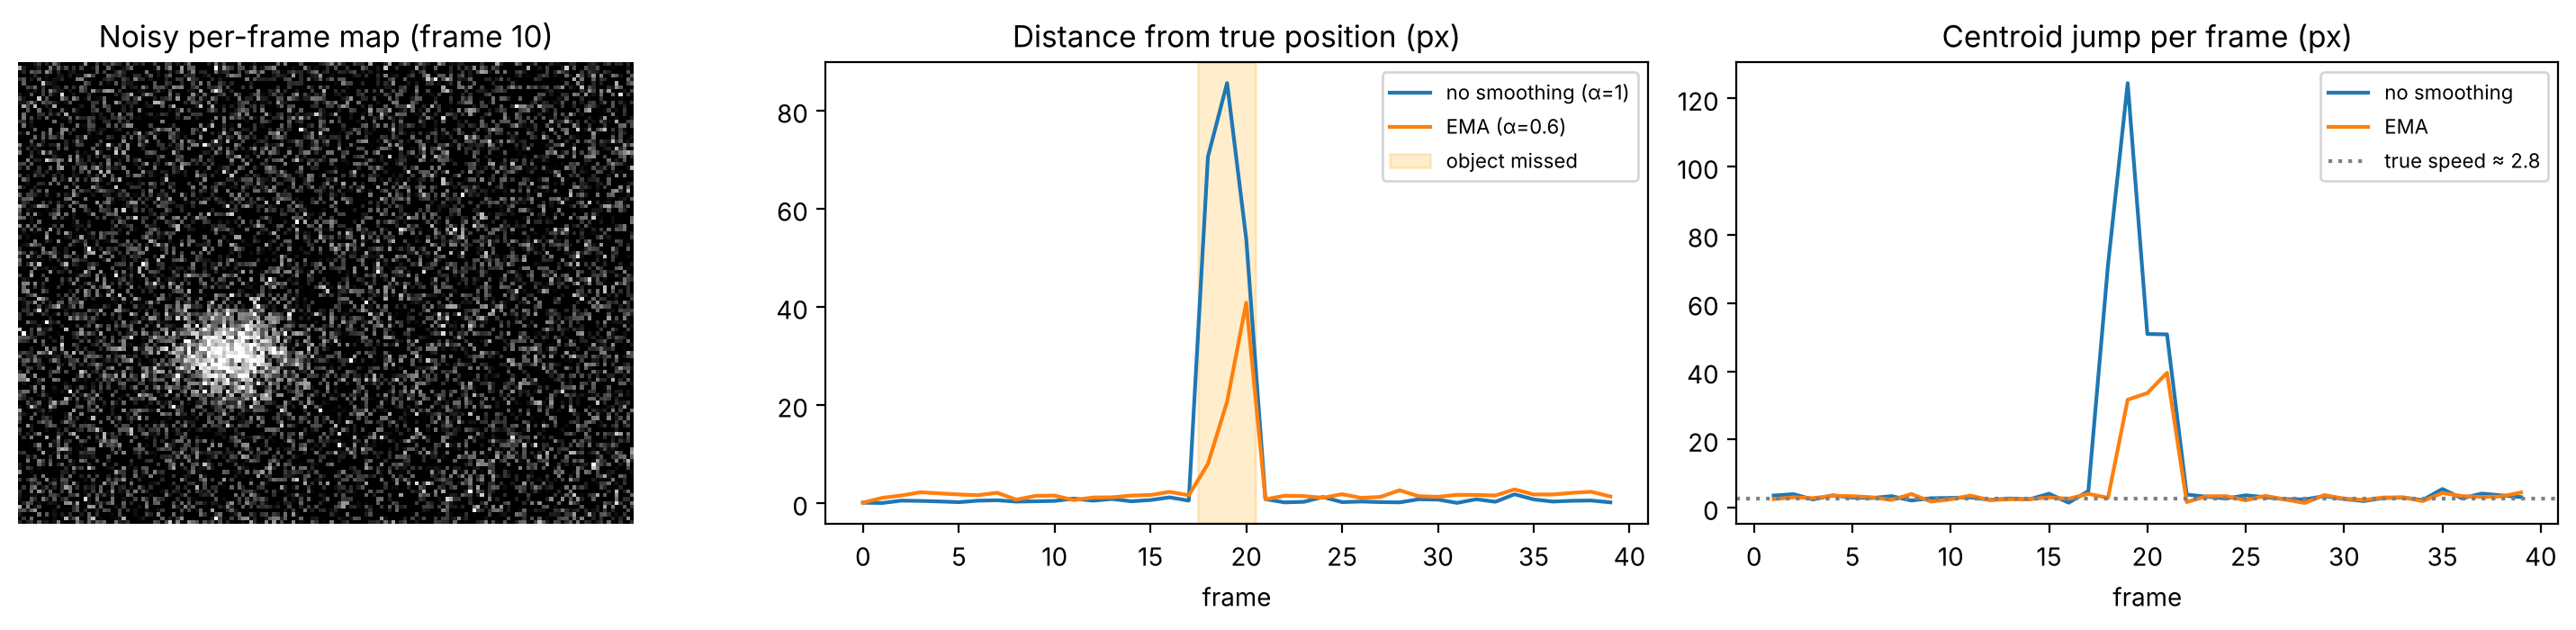

No smoothing  detection rate=1.00   mean error from truth= 5.72 px   mean centroid jump=10.40 px/frame
EMA α=0.6     detection rate=1.00   mean error from truth= 3.18 px   mean centroid jump= 5.40 px/frame


In [17]:
# DEMO (no weights needed): why temporal smoothing helps.
# We simulate per-frame camouflage maps of ONE moving object with heavy noise (camouflage = weak,
# unreliable evidence) and 3 frames (18-20) where the detector completely loses the object.
# Same maps go to two trackers: without smoothing (alpha = 1) and with EMA (alpha = 0.6).
T, Hh, Ww = 40, 120, 160
yy, xx = np.mgrid[0:Hh, 0:Ww]
rng = np.random.default_rng(0)
maps, truth = [], []
for t in range(T):
    cx, cy = 30 + 2.5 * t, 60 + 15 * np.sin(t / 6)                         # true path of the object
    truth.append((cx, cy))
    blob = np.exp(-(((xx - cx) / 14) ** 2 + ((yy - cy) / 10) ** 2))
    strength = 0.0 if t in (18, 19, 20) else 1.0                           # detector misses the object
    maps.append(np.clip(strength * blob + 0.3 * rng.standard_normal((Hh, Ww)), 0, 1))

raw, ema = TemporalTracker(alpha=1.0), TemporalTracker(alpha=0.6)         # alpha = 1 -> no smoothing
for t, C in enumerate(maps):
    raw.update(C, t); ema.update(C, t)

def err_series(log):
    return [np.hypot(r['cx'] - truth[r['frame']][0], r['cy'] - truth[r['frame']][1]) if r['detected'] else np.nan for r in log]
def jump_series(log):
    return [r['disp'] if r['detected'] and r['disp'] is not None else np.nan for r in log]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].imshow(maps[10], cmap='gray'); ax[0].set_title('Noisy per-frame map (frame 10)'); ax[0].axis('off')
ax[1].plot(err_series(raw.log), label='no smoothing (α=1)'); ax[1].plot(err_series(ema.log), label='EMA (α=0.6)')
ax[1].axvspan(17.5, 20.5, color='orange', alpha=.2, label='object missed'); ax[1].set_title('Distance from true position (px)'); ax[1].legend(fontsize=8)
ax[2].plot(jump_series(raw.log), label='no smoothing'); ax[2].plot(jump_series(ema.log), label='EMA')
ax[2].axhline(2.8, color='gray', ls=':', label='true speed ≈ 2.8'); ax[2].set_title('Centroid jump per frame (px)'); ax[2].legend(fontsize=8)
for a in ax[1:]: a.set_xlabel('frame')
plt.tight_layout(); plt.show()

for name, trk in [('No smoothing', raw), ('EMA α=0.6', ema)]:
    print(f'{name:<13s} detection rate={np.mean([r["detected"] for r in trk.log]):.2f}   '
          f'mean error from truth={np.nanmean(err_series(trk.log)):5.2f} px   '
          f'mean centroid jump={np.nanmean(jump_series(trk.log)):5.2f} px/frame')

**What the demo shows:** when the detector loses the object for 3 frames (orange band), the unsmoothed tracker jumps to random noise blobs (error ~85 px). EMA keeps part of the previous frames' evidence, so the error stays much lower and the track jumps less. On normal frames, EMA lags the object by about 1–2 px. That is the price of stability, controlled by α.

In [18]:
# Run the real video pipeline if weights and a video are available
if sinet is not None and os.path.exists(INPUT_VIDEO):
    log = run_video(sinet, INPUT_VIDEO, out_dir='./VideoResult', alpha=0.6, tau=0.5, max_frames=300)
else:
    print('Needs pretrained weights + input video. Set MODEL_PATH and INPUT_VIDEO in Part 1 (or use the Colab notebook).')

Needs pretrained weights + input video. Set MODEL_PATH and INPUT_VIDEO in Part 1 (or use the Colab notebook).


---
## Summary
| Stage | Module | Output |
|---|---|---|
| Features | ResNet-50 (two branches for layers 3–4) | X0…X4 |
| Search | 4 × RF → PDC_SM | coarse map $C_s$ (44×44) |
| Bridge | Search Attention (Gaussian + max) | $C_h = X_2 \otimes \max(\tilde A, A)$ |
| Identify | layer3_2/4_2 → 3 × RF → PDC_IM | refined map $C_i$ |
| Training | BCE on both maps | $\mathcal{L}=\mathcal{L}_s+\mathcal{L}_i$ |
| **Ours: video** | EMA + threshold + connected component | mask, box, centroid track |

**Credits:** model code by Fan et al., *Camouflaged Object Detection*, CVPR 2020 (github.com/DengPingFan/SINet). Parts 8 (modernised training), 9 and 10 were written by our group.